# TP Jour 4 - UC-08 : analyses des donnees et visualisation

Notebook d'analyse execute dans la VM Ubuntu (env conda `j3` : Python 3.10 /
PySpark 3.5.5 / pandas / matplotlib).

Jeux utilises : Silver `store_sales`, `item`, `store`, `date_dim` et Gold
`ventes_mensuelles_magasin`, produits au Jour 3.

Objectifs : verifier les jeux, calculer les KPI du dictionnaire UC-01, produire
des statistiques descriptives, deux analyses metier et des visualisations.

## 1. Environnement et chargement des donnees

Session Spark en mode `local[2]`, lecture des Parquet Silver/Gold produits au
Jour 3.

In [1]:
import os, sys
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
J3 = os.environ.get("J3_OUT_DIR", "/home/amani/j3_data")
J4 = os.environ.get("J4_OUT_DIR", "/home/amani/j4_data")
OUT = os.path.join(J4, "outputs"); VIS = os.path.join(J4, "visualisations")
for d in (OUT, VIS):
    os.makedirs(d, exist_ok=True)
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName("TP4-analyses")
         .master("local[2]").getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version)

26/11/21 19:10:26 WARN Utils: Your hostname, ubuntu resolves to a loopback address: 127.0.1.1; using 10.0.2.15 instead (on interface enp0s3)
26/11/21 19:10:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/21 19:10:28 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.5


In [2]:
SILVER = os.path.join(J3, "silver")
GOLD = os.path.join(J3, "gold", "ventes_mensuelles_magasin")
ventes = spark.read.parquet(os.path.join(SILVER, "store_sales"))
item   = spark.read.parquet(os.path.join(SILVER, "item"))
mag    = spark.read.parquet(os.path.join(SILVER, "store"))
dates  = spark.read.parquet(os.path.join(SILVER, "date_dim"))
gold   = spark.read.parquet(GOLD)
for nom, df in [("silver/store_sales", ventes), ("silver/item", item),
                ("silver/store", mag), ("silver/date_dim", dates),
                ("gold/ventes_mensuelles_magasin", gold)]:
    print("{0:35} {1:>7} lignes, {2} colonnes".format(
        nom, df.count(), len(df.columns)))
gold.printSchema()

silver/store_sales                   667579 lignes, 23 colonnes


silver/item                           17820 lignes, 22 colonnes


silver/store                             12 lignes, 29 colonnes


silver/date_dim                      109573 lignes, 28 colonnes


gold/ventes_mensuelles_magasin          720 lignes, 8 colonnes
root
 |-- s_store_sk: long (nullable = true)
 |-- s_store_name: string (nullable = true)
 |-- d_year: long (nullable = true)
 |-- d_moy: long (nullable = true)
 |-- ca_net: double (nullable = true)
 |-- quantite_vendue: long (nullable = true)
 |-- nb_lignes_vente: long (nullable = true)
 |-- marge_nette: double (nullable = true)



## 2. Verification des schemas et volumes

Les jeux correspondent aux productions du Jour 3 : 667 579 lignes de ventes en
Silver, 720 lignes agregees en Gold (12 magasins x 60 mois). Les controles
qualite du Jour 3 (21/21 OK) garantissent l'integrite referentielle des
jointures utilisees ici.

In [3]:
ventes.printSchema()
ventes.show(3, truncate=40)

root
 |-- ss_sold_date_sk: long (nullable = true)
 |-- ss_sold_time_sk: long (nullable = true)
 |-- ss_item_sk: long (nullable = true)
 |-- ss_customer_sk: long (nullable = true)
 |-- ss_cdemo_sk: long (nullable = true)
 |-- ss_hdemo_sk: long (nullable = true)
 |-- ss_addr_sk: long (nullable = true)
 |-- ss_store_sk: long (nullable = true)
 |-- ss_promo_sk: long (nullable = true)
 |-- ss_ticket_number: long (nullable = true)
 |-- ss_quantity: integer (nullable = true)
 |-- ss_wholesale_cost: double (nullable = true)
 |-- ss_list_price: double (nullable = true)
 |-- ss_sales_price: double (nullable = true)
 |-- ss_ext_discount_amt: double (nullable = true)
 |-- ss_ext_sales_price: double (nullable = true)
 |-- ss_ext_wholesale_cost: double (nullable = true)
 |-- ss_ext_list_price: double (nullable = true)
 |-- ss_ext_tax: double (nullable = true)
 |-- ss_coupon_amt: double (nullable = true)
 |-- ss_net_paid: double (nullable = true)
 |-- ss_net_paid_inc_tax: double (nullable = true)
 |-

+---------------+---------------+----------+--------------+-----------+-----------+----------+-----------+-----------+----------------+-----------+-----------------+-------------+--------------+-------------------+------------------+---------------------+-----------------+----------+-------------+-----------+-------------------+-------------+
|ss_sold_date_sk|ss_sold_time_sk|ss_item_sk|ss_customer_sk|ss_cdemo_sk|ss_hdemo_sk|ss_addr_sk|ss_store_sk|ss_promo_sk|ss_ticket_number|ss_quantity|ss_wholesale_cost|ss_list_price|ss_sales_price|ss_ext_discount_amt|ss_ext_sales_price|ss_ext_wholesale_cost|ss_ext_list_price|ss_ext_tax|ss_coupon_amt|ss_net_paid|ss_net_paid_inc_tax|ss_net_profit|
+---------------+---------------+----------+--------------+-----------+-----------+----------+-----------+-----------+----------------+-----------+-----------------+-------------+--------------+-------------------+------------------+---------------------+-----------------+----------+-------------+-----------+

## 3. Calcul des KPI (dictionnaire UC-01)

KPI retenus, calculables sur les champs disponibles : K01 CA net magasin,
K03 nombre de transactions, K04 panier moyen, K05 quantites vendues,
K07 taux de remise, K08 marge nette.

In [4]:
agg = ventes.agg(
    F.round(F.sum("ss_net_paid"), 2).alias("k01"),
    F.countDistinct("ss_ticket_number").alias("k03"),
    F.round(F.sum("ss_quantity"), 0).alias("k05"),
    F.round(F.sum("ss_ext_discount_amt"), 2).alias("remise"),
    F.round(F.sum("ss_ext_list_price"), 2).alias("catalogue"),
    F.round(F.sum("ss_net_profit"), 2).alias("k08")).first()
k01 = float(agg["k01"]); k03 = int(agg["k03"]); k04 = round(k01 / k03, 2)
k05 = int(agg["k05"]); k07 = round(100.0 * agg["remise"] / agg["catalogue"], 2)
k08 = float(agg["k08"]); k08t = round(100.0 * k08 / k01, 2)
import pandas as pd
kpi = pd.DataFrame([
    ("K01", "Chiffre d'affaires net magasin", "SUM(ss_net_paid)", k01, "$"),
    ("K03", "Nombre de transactions", "COUNT(DISTINCT ss_ticket_number)", k03, "tickets"),
    ("K04", "Panier moyen", "K01 / K03", k04, "$/transaction"),
    ("K05", "Quantites vendues", "SUM(ss_quantity)", k05, "unites"),
    ("K07", "Taux de remise",
     "SUM(ss_ext_discount_amt)/SUM(ss_ext_list_price)*100", k07, "%"),
    ("K08", "Marge nette", "SUM(ss_net_profit)", k08, "$"),
    ("K08b", "Taux de marge", "K08/K01*100", k08t, "%"),
], columns=["id", "nom", "formule", "valeur", "unite"])
print(kpi.to_string(index=False))
kpi.to_csv(os.path.join(OUT, "kpi.csv"), index=False)

  id                            nom                                             formule        valeur         unite
 K01 Chiffre d'affaires net magasin                                    SUM(ss_net_paid)  1.150530e+09             $
 K03         Nombre de transactions                    COUNT(DISTINCT ss_ticket_number)  8.910000e+04       tickets
 K04                   Panier moyen                                           K01 / K03  1.291279e+04 $/transaction
 K05              Quantites vendues                                    SUM(ss_quantity)  3.375547e+07        unites
 K07                 Taux de remise SUM(ss_ext_discount_amt)/SUM(ss_ext_list_price)*100  4.999000e+01             %
 K08                    Marge nette                                  SUM(ss_net_profit) -5.525534e+08             $
K08b                  Taux de marge                                         K08/K01*100 -4.803000e+01             %


In [5]:
# controle : CA net par annee (comparaison avec les valeurs du dictionnaire UC-01)
ca_annee = (ventes.join(dates.select("d_date_sk", "d_year"),
            ventes["ss_sold_date_sk"] == dates["d_date_sk"], "left")
    .groupBy("d_year")
    .agg(F.round(F.sum("ss_net_paid"), 2).alias("ca_net"),
         F.countDistinct("ss_ticket_number").alias("transactions"))
    .orderBy("d_year"))
ca_annee.show()
ca_annee.toPandas().to_csv(os.path.join(OUT, "ca_par_annee.csv"), index=False)

+------+--------------+------------+
|d_year|        ca_net|transactions|
+------+--------------+------------+
|  2001|2.3249865983E8|       17991|
|  2002|2.3094726582E8|       17990|
|  2003|2.3357518563E8|       17990|
|  2004|2.3434493429E8|       18039|
|  2005| 2.191635408E8|       17090|
+------+--------------+------------+



## 4. Statistiques descriptives

Sur `silver/store_sales` : volumes, min/max/moyenne/mediane des montants et
quantites, nombre d'articles, magasins et clients distincts.

In [6]:
stats = (ventes.select(
    F.count("*").alias("nb_lignes"),
    F.round(F.min("ss_net_paid"), 2).alias("net_paid_min"),
    F.round(F.max("ss_net_paid"), 2).alias("net_paid_max"),
    F.round(F.mean("ss_net_paid"), 2).alias("net_paid_moyenne"),
    F.round(F.expr("percentile_approx(ss_net_paid,0.5)"), 2).alias("net_paid_mediane"),
    F.min("ss_quantity").alias("quantite_min"),
    F.max("ss_quantity").alias("quantite_max"),
    F.round(F.mean("ss_quantity"), 2).alias("quantite_moyenne"),
    F.countDistinct("ss_item_sk").alias("articles_distincts"),
    F.countDistinct("ss_store_sk").alias("magasins_distincts"),
    F.countDistinct("ss_customer_sk").alias("clients_distincts")).first())
for k, v in stats.asDict().items():
    print("{0:22} {1}".format(k, v))
pd.DataFrame([stats.asDict()]).to_csv(
    os.path.join(OUT, "stats_descriptives.csv"), index=False)
per = (ventes.join(dates.select("d_date_sk", "d_date"),
       ventes["ss_sold_date_sk"] == dates["d_date_sk"], "left")
       .agg(F.min("d_date"), F.max("d_date")).first())
print("periode couverte :", per[0], "->", per[1])

nb_lignes              667579
net_paid_min           0.0
net_paid_max           18745.0
net_paid_moyenne       1723.44
net_paid_mediane       878.6
quantite_min           1
quantite_max           100
quantite_moyenne       50.56
articles_distincts     17820
magasins_distincts     12
clients_distincts      37336


periode couverte : 2001-01-01 -> 2005-12-13


## 5. Analyse metier 1 : evolution du CA net par mois

Question UC-01 : *comment evoluent les ventes dans le temps ?* Le jeu Gold
fournit deja l'agregat mensuel par magasin ; on le regroupe par mois
calendaire.

In [7]:
mensuel = (gold.groupBy("d_year", "d_moy")
    .agg(F.round(F.sum("ca_net"), 2).alias("ca_net"),
         F.sum("quantite_vendue").alias("quantites"))
    .orderBy("d_year", "d_moy"))
pdf_m = mensuel.toPandas()
pdf_m["mois"] = (pdf_m["d_year"].astype(str) + "-"
                 + pdf_m["d_moy"].astype(str).str.zfill(2))
pdf_m.to_csv(os.path.join(OUT, "ca_mensuel.csv"), index=False)
pdf_m.head(10)

,d_year,d_moy,ca_net,quantites,mois
0,2001,1,19279633.40,574902,2001-01
1,2001,2,17989228.47,529739,2001-02
2,2001,3,19630651.08,569439,2001-03
3,2001,4,18915426.86,557668,2001-04
4,2001,5,19786451.19,584690,2001-05
5,2001,6,19399244.10,562702,2001-06
6,2001,7,19985336.68,576657,2001-07
7,2001,8,19552826.03,578727,2001-08
8,2001,9,19442330.41,567922,2001-09
9,2001,10,20078324.18,578060,2001-10


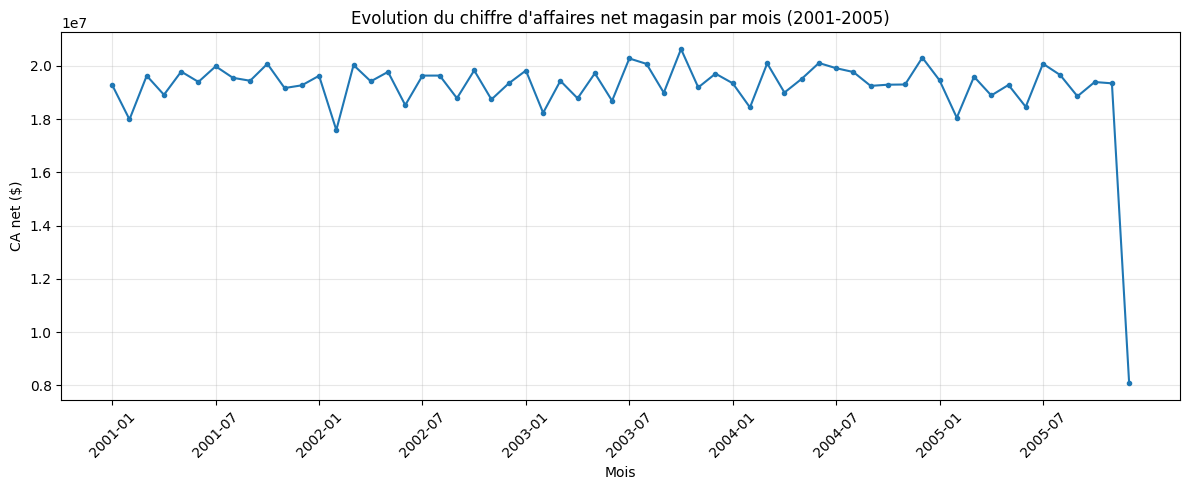

meilleur mois : ['2003-10', np.float64(20632952.65)]
moins bon mois : ['2005-12', np.float64(8078218.76)]
mois civils des 12 meilleurs mois : {'07': np.int64(4), '10': np.int64(3), '03': np.int64(2), '12': np.int64(1), '06': np.int64(1), '08': np.int64(1)}


In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(pdf_m["mois"], pdf_m["ca_net"], marker="o", markersize=3)
plt.title("Evolution du chiffre d'affaires net magasin par mois (2001-2005)")
plt.xlabel("Mois"); plt.ylabel("CA net ($)")
pas = list(range(0, len(pdf_m), 6))
plt.xticks(pas, pdf_m["mois"].iloc[pas], rotation=45)
plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(VIS, "visualisation_2_evolution_ca_mensuel.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print("meilleur mois :",
      pdf_m.loc[pdf_m["ca_net"].idxmax(), ["mois", "ca_net"]].tolist())
print("moins bon mois :",
      pdf_m.loc[pdf_m["ca_net"].idxmin(), ["mois", "ca_net"]].tolist())
print("mois civils des 12 meilleurs mois :",
      dict(pdf_m.nlargest(12, "ca_net")["mois"].str[-2:].value_counts()))

## 6. Analyse metier 2 : comparaison des magasins

Question UC-01 : *quelles differences observe-t-on entre les magasins ?*
CA net total, quantites, marge et panier moyen (CA/transactions) par magasin.

In [9]:
par_mag = (gold.groupBy("s_store_sk", "s_store_name")
    .agg(F.round(F.sum("ca_net"), 2).alias("ca_net"),
         F.sum("quantite_vendue").alias("quantites"),
         F.round(F.sum("marge_nette"), 2).alias("marge"))
    .orderBy(F.desc("ca_net")))
pdf_s = par_mag.toPandas()
trans = (ventes.groupBy("ss_store_sk")
         .agg(F.countDistinct("ss_ticket_number").alias("transactions")))
pdf_s = pdf_s.merge(
    trans.toPandas().rename(columns={"ss_store_sk": "s_store_sk"}),
    on="s_store_sk")
pdf_s["panier_moyen"] = (pdf_s["ca_net"] / pdf_s["transactions"]).round(2)
pdf_s.to_csv(os.path.join(OUT, "ca_par_magasin.csv"), index=False)
print(pdf_s.to_string(index=False))
print("ecart max/min vs moyenne :",
      round(100.0 * (pdf_s["ca_net"].max() - pdf_s["ca_net"].min())
            / pdf_s["ca_net"].mean(), 2), "%")

 s_store_sk s_store_name      ca_net  quantites        marge  transactions  panier_moyen
          7      Buffalo 98950137.76    2915053 -47643702.48          7645      12943.12
          4      Elmwood 96770105.59    2832572 -46245313.52          7462      12968.39
          9   Germantown 96748356.68    2830684 -46015802.68          7435      13012.56
          0       Forest 96727851.94    2830581 -46086598.19          7456      12973.16
          8 Williamstown 96578622.89    2821869 -45837269.98          7414      13026.52
          3      Pioneer 96063990.59    2800824 -45725385.12          7396      12988.64
          1     Hillside 95929844.66    2817524 -46172561.01          7422      12925.07
         11      Bedford 95607843.48    2790631 -45346473.98          7449      12834.99
          6   Bloomfield 94751173.08    2780253 -45805948.18          7284      13008.12
         10       Avalon 94263977.55    2785773 -46326552.26          7409      12722.90
          5        Eg

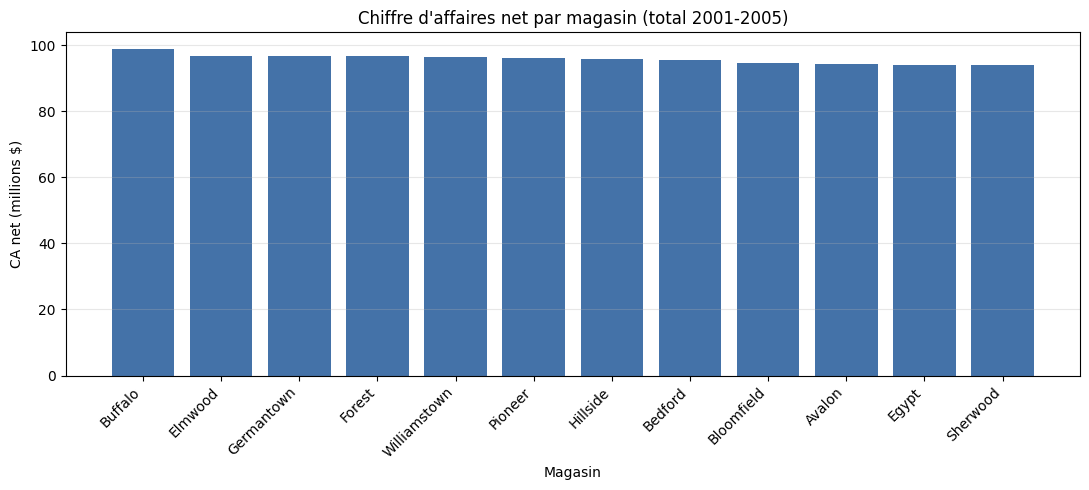

In [10]:
plt.figure(figsize=(11, 5))
plt.bar(pdf_s["s_store_name"], pdf_s["ca_net"] / 1e6, color="#4472A8")
plt.title("Chiffre d'affaires net par magasin (total 2001-2005)")
plt.xlabel("Magasin"); plt.ylabel("CA net (millions $)")
plt.xticks(rotation=45, ha="right"); plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(VIS, "visualisation_1_ca_par_magasin.png"),
            dpi=150, bbox_inches="tight")
plt.show()

## 7. Complement : CA par categorie de produit

Jointure `store_sales` -> `item` (0 orphelin, verifiee au Jour 3) pour le CA
par categorie.

              i_category       ca_net  quantites
                   Music 519666693.84   15238374
                   Books 307151503.25    9007511
             Movies & TV  74735891.89    2189279
  Clothing & Accessories  56754855.82    1640550
             Electronics  55715087.49    1632098
          Home & Kitchen  41260511.11    1226839
       Sports & Outdoors  40926938.33    1209305
            Toys & Games  27437825.33     809999
Tools & Home Improvement  26880279.31     801519


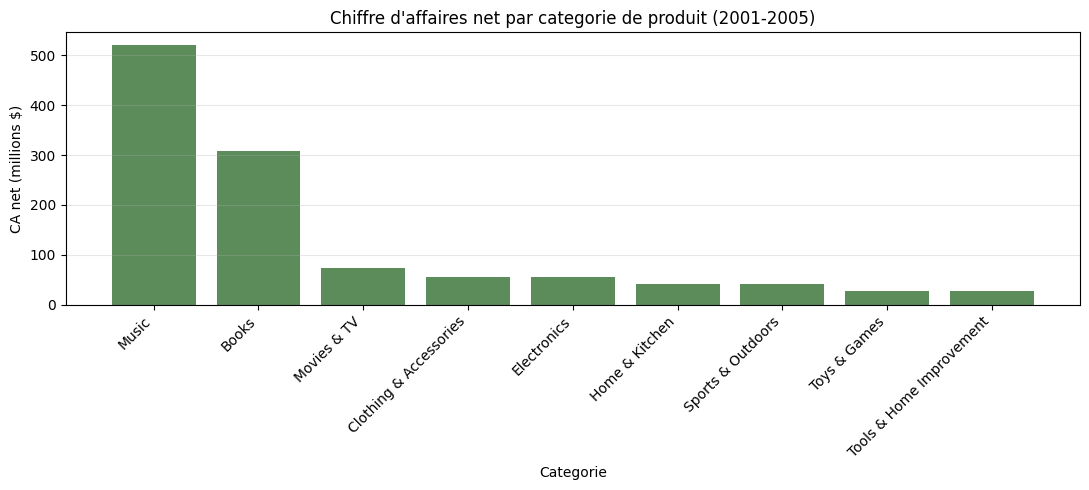

In [11]:
par_cat = (ventes.join(item.select("i_item_sk", "i_category"),
           ventes["ss_item_sk"] == item["i_item_sk"], "left")
    .groupBy("i_category")
    .agg(F.round(F.sum("ss_net_paid"), 2).alias("ca_net"),
         F.sum("ss_quantity").alias("quantites"))
    .orderBy(F.desc("ca_net")))
pdf_c = par_cat.toPandas()
pdf_c.to_csv(os.path.join(OUT, "ca_par_categorie.csv"), index=False)
print(pdf_c.to_string(index=False))
plt.figure(figsize=(11, 5))
plt.bar(pdf_c["i_category"], pdf_c["ca_net"] / 1e6, color="#5B8C5A")
plt.title("Chiffre d'affaires net par categorie de produit (2001-2005)")
plt.xlabel("Categorie"); plt.ylabel("CA net (millions $)")
plt.xticks(rotation=45, ha="right"); plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(VIS, "visualisation_3_ca_par_categorie.png"),
            dpi=150, bbox_inches="tight")
plt.show()

## 8. Constats, limites et recommandations

Les interpretations detaillees sont dans le rapport UC-08. En synthese :

- les 12 magasins ont des CA quasi identiques (donnees synthetiques uniformes) ;
- une saisonnalite marquee apparait sur certains mois ;
- la marge nette est negative partout : artefact du generateur TPCx-BB,
  a ne pas exploiter comme indicateur de rentabilite.

Les resultats sont recalculables integralement par `scripts/analyses.py` ou
par l'execution de ce notebook. Rappel : les donnees TPCx-BB sont synthetiques ;
les constats portent sur la demarche, pas sur une entreprise reelle.

In [12]:
print("fichiers produits :")
for d in (OUT, VIS):
    for f in sorted(os.listdir(d)):
        print("  ", os.path.join(d, f))
spark.stop()
print("TERMINE")

fichiers produits :
   /home/amani/j4_data/outputs/ca_mensuel.csv
   /home/amani/j4_data/outputs/ca_par_annee.csv
   /home/amani/j4_data/outputs/ca_par_categorie.csv
   /home/amani/j4_data/outputs/ca_par_magasin.csv
   /home/amani/j4_data/outputs/kpi.csv
   /home/amani/j4_data/outputs/stats_descriptives.csv
   /home/amani/j4_data/visualisations/visualisation_1_ca_par_magasin.png
   /home/amani/j4_data/visualisations/visualisation_2_evolution_ca_mensuel.png
   /home/amani/j4_data/visualisations/visualisation_3_ca_par_categorie.png


TERMINE
